In [8]:
# ================================================
# Notebook 03: Modelos Baseline
# Autor: Steeven Quezada
# ================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import warnings
warnings.filterwarnings('ignore')

sys.path.append('../src')
from feature_extraction import get_tfidf_features, save_vectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, f1_score, accuracy_score
)

# ================================================
# PASO 1: CARGA DE DATOS
# ================================================
df = pd.read_csv('../data/processed/dataset_preprocessed.csv', 
                 low_memory=False)
print(f"Dataset cargado: {len(df):,} registros")
print(f"Distribución: Falsas {(df['label']==0).sum():,} | Reales {(df['label']==1).sum():,}")

Dataset cargado: 38,473 registros
Distribución: Falsas 17,282 | Reales 21,191


In [9]:
# ================================================
# NOTA METODOLÓGICA: DESBALANCE DE CLASES
# ================================================
print("=== ANÁLISIS DE DESBALANCE ===")
falsas = (df['label']==0).sum()
reales = (df['label']==1).sum()
total  = len(df)

print(f"Falsas: {falsas:,} ({falsas/total*100:.1f}%)")
print(f"Reales: {reales:,} ({reales/total*100:.1f}%)")
print(f"Ratio:  {reales/falsas:.2f}:1")
print(f"""
Observación: el dataset presenta un leve desbalance de clases
(55.1% reales vs 44.9% falsas). Este desbalance es moderado
y no requiere técnicas de sobremuestreo (SMOTE) ni pesos de
clase diferenciados, dado que:
  1. La diferencia es de ~10 puntos porcentuales
  2. Se aplicó stratify=y en el split train/test
  3. Los modelos reportan F1-score balanceado en ambas clases
Este hallazgo se documenta como limitación del dataset original.
""")

=== ANÁLISIS DE DESBALANCE ===
Falsas: 17,282 (44.9%)
Reales: 21,191 (55.1%)
Ratio:  1.23:1

Observación: el dataset presenta un leve desbalance de clases
(55.1% reales vs 44.9% falsas). Este desbalance es moderado
y no requiere técnicas de sobremuestreo (SMOTE) ni pesos de
clase diferenciados, dado que:
  1. La diferencia es de ~10 puntos porcentuales
  2. Se aplicó stratify=y en el split train/test
  3. Los modelos reportan F1-score balanceado en ambas clases
Este hallazgo se documenta como limitación del dataset original.



In [10]:
# ================================================
# PASO 2: FUNCIÓN DE EVALUACIÓN
# ================================================

def evaluar_modelo(modelo, X_train, X_test, y_train, y_test, nombre):
    """
    Entrena y evalúa un modelo. Retorna métricas completas.
    """
    # Entrenar
    modelo.fit(X_train, y_train)
    
    # Predecir
    y_pred = modelo.predict(X_test)
    
    # Métricas
    acc  = accuracy_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred, average='weighted')
    
    try:
        auc = roc_auc_score(y_test, modelo.predict_proba(X_test)[:,1])
    except:
        auc = None  # LinearSVC no tiene predict_proba
    
    print(f"\n{'─'*40}")
    print(f"Modelo: {nombre}")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    if auc:
        print(f"  AUC-ROC:   {auc:.4f}")
    print(f"\nReporte detallado:")
    print(classification_report(y_test, y_pred, 
          target_names=['Falsa', 'Real']))
    
    return {
        'modelo': nombre,
        'accuracy': acc,
        'f1': f1,
        'auc': auc,
        'y_pred': y_pred,
        'objeto': modelo
    }

In [11]:
# ================================================
# PASO 3: ENTRENAMIENTO Y EVALUACIÓN
# ================================================

modelos = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Naive Bayes':         MultinomialNB(),
    'SVM':                 LinearSVC(max_iter=2000, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, 
                                                   random_state=42, n_jobs=-1),
}

enfoques = ['text_clean', 'title_clean', 'title_text_clean']
resultados = {}

for enfoque in enfoques:
    print(f"\n{'='*50}")
    print(f"ENFOQUE: {enfoque}")
    print(f"{'='*50}")
    
    X_train, X_test, y_train, y_test, vec = get_tfidf_features(df, enfoque)
    save_vectorizer(vec, enfoque, path='../models/')
    
    resultados[enfoque] = []
    
    for nombre, modelo in modelos.items():
        resultado = evaluar_modelo(
            modelo, X_train, X_test, 
            y_train, y_test, nombre
        )
        resultado['enfoque'] = enfoque
        resultados[enfoque].append(resultado)


ENFOQUE: text_clean
Enfoque: 'text_clean'
  Train: 30,778 muestras | 10,000 features
  Test:  7,695 muestras  | 10,000 features
  Balance train — Falsas: 13,825 | Reales: 16,953
  ✓ Vectorizador guardado en ../models/tfidf_text_clean.pkl

────────────────────────────────────────
Modelo: Logistic Regression
  Accuracy:  0.9866
  F1-score:  0.9866
  AUC-ROC:   0.9987

Reporte detallado:
              precision    recall  f1-score   support

       Falsa       0.99      0.98      0.98      3457
        Real       0.98      0.99      0.99      4238

    accuracy                           0.99      7695
   macro avg       0.99      0.99      0.99      7695
weighted avg       0.99      0.99      0.99      7695


────────────────────────────────────────
Modelo: Naive Bayes
  Accuracy:  0.9463
  F1-score:  0.9463
  AUC-ROC:   0.9859

Reporte detallado:
              precision    recall  f1-score   support

       Falsa       0.94      0.94      0.94      3457
        Real       0.95      0.95

=== TABLA COMPARATIVA DE MODELOS BASELINE ===

   Enfoque              Modelo Accuracy F1-score AUC-ROC
      text Logistic Regression   0.9866   0.9866  0.9987
      text         Naive Bayes   0.9463   0.9463  0.9859
      text                 SVM   0.9938   0.9938     N/D
      text       Random Forest   0.9918   0.9918  0.9996
     title Logistic Regression   0.9311   0.9309  0.9815
     title         Naive Bayes   0.9232   0.9231  0.9781
     title                 SVM   0.9346   0.9346     N/D
     title       Random Forest   0.9162   0.9160  0.9728
title+text Logistic Regression   0.9869   0.9869  0.9989
title+text         Naive Bayes   0.9471   0.9471  0.9871
title+text                 SVM   0.9945   0.9945     N/D
title+text       Random Forest   0.9921   0.9921  0.9997


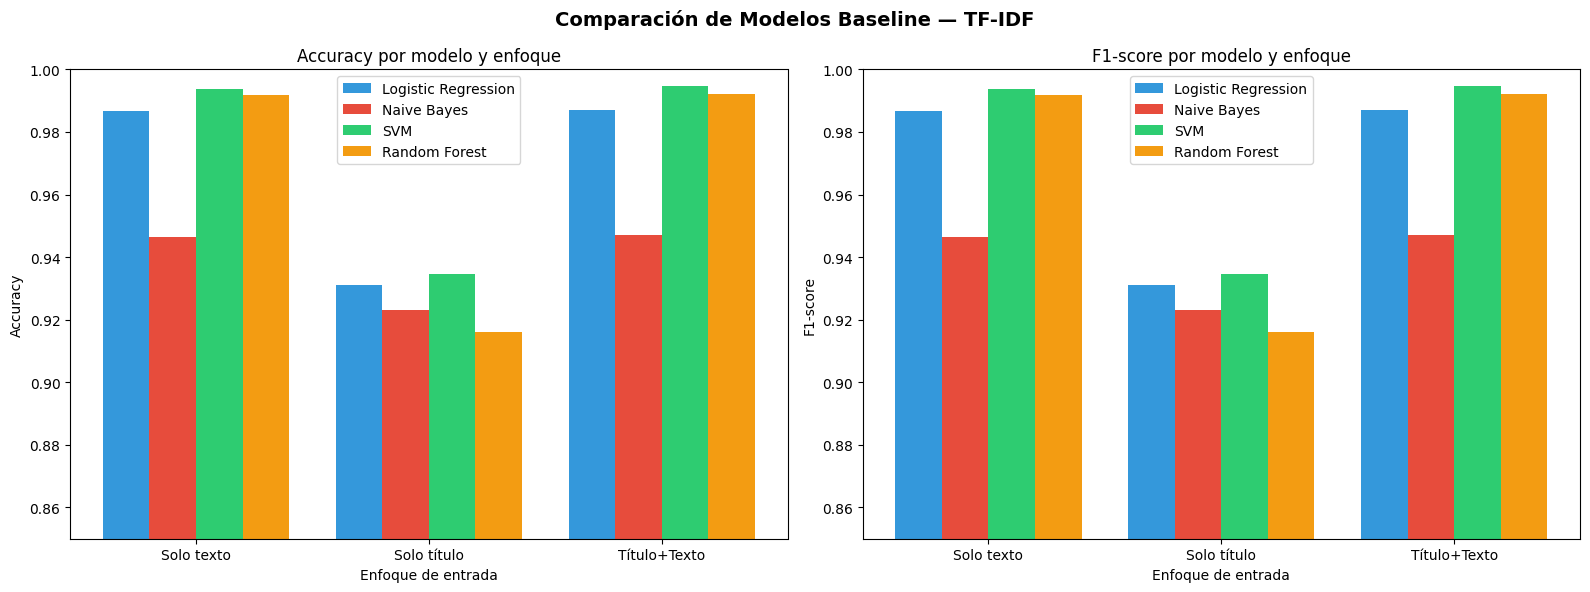

✓ Gráfico guardado en reports/


In [12]:
# ================================================
# PASO 4: TABLA COMPARATIVA Y VISUALIZACIÓN
# ================================================

# Construir tabla de resultados
filas = []
for enfoque, lista in resultados.items():
    for r in lista:
        filas.append({
            'Enfoque': enfoque.replace('_clean', '').replace('_', '+'),
            'Modelo': r['modelo'],
            'Accuracy': f"{r['accuracy']:.4f}",
            'F1-score': f"{r['f1']:.4f}",
            'AUC-ROC': f"{r['auc']:.4f}" if r['auc'] else 'N/D'
        })

tabla = pd.DataFrame(filas)
print("=== TABLA COMPARATIVA DE MODELOS BASELINE ===\n")
print(tabla.to_string(index=False))

# Gráfico comparativo
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

enfoques_labels = ['Solo texto', 'Solo título', 'Título+Texto']
modelos_labels = ['Logistic Regression', 'Naive Bayes', 'SVM', 'Random Forest']
colores = ['#3498DB', '#E74C3C', '#2ECC71', '#F39C12']

# Accuracy por enfoque y modelo
accuracies = []
for enfoque in enfoques:
    accs = [r['accuracy'] for r in resultados[enfoque]]
    accuracies.append(accs)

x = np.arange(len(enfoques_labels))
width = 0.2

for i, (modelo, color) in enumerate(zip(modelos_labels, colores)):
    vals = [accuracies[j][i] for j in range(3)]
    axes[0].bar(x + i*width, vals, width, label=modelo, color=color)

axes[0].set_xlabel('Enfoque de entrada')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy por modelo y enfoque')
axes[0].set_xticks(x + width*1.5)
axes[0].set_xticklabels(enfoques_labels)
axes[0].legend()
axes[0].set_ylim(0.85, 1.0)

# F1 por enfoque y modelo
f1s = []
for enfoque in enfoques:
    f1_vals = [r['f1'] for r in resultados[enfoque]]
    f1s.append(f1_vals)

for i, (modelo, color) in enumerate(zip(modelos_labels, colores)):
    vals = [f1s[j][i] for j in range(3)]
    axes[1].bar(x + i*width, vals, width, label=modelo, color=color)

axes[1].set_xlabel('Enfoque de entrada')
axes[1].set_ylabel('F1-score')
axes[1].set_title('F1-score por modelo y enfoque')
axes[1].set_xticks(x + width*1.5)
axes[1].set_xticklabels(enfoques_labels)
axes[1].legend()
axes[1].set_ylim(0.85, 1.0)

plt.suptitle('Comparación de Modelos Baseline — TF-IDF',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/06_baseline_comparacion.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Gráfico guardado en reports/")

Enfoque: 'title_text_clean'
  Train: 30,778 muestras | 10,000 features
  Test:  7,695 muestras  | 10,000 features
  Balance train — Falsas: 13,825 | Reales: 16,953


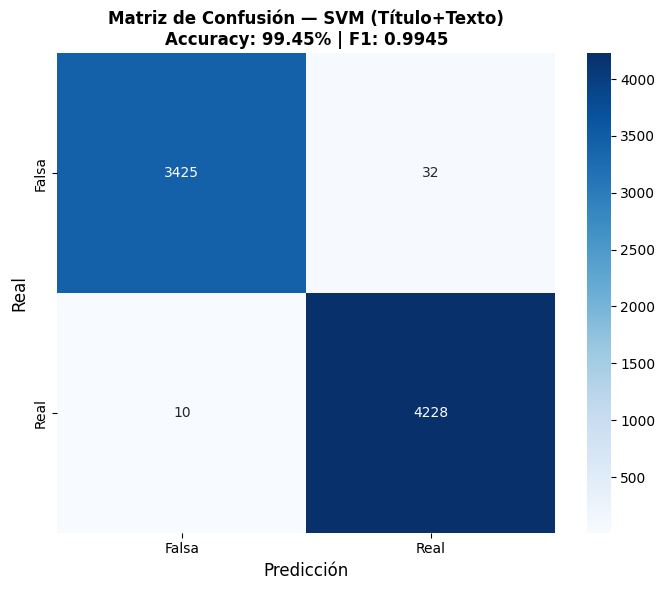


=== RESUMEN FINAL — MODELOS BASELINE ===
Mejor modelo:  SVM con Título+Texto
Accuracy:      99.45%
F1-score:      0.9945
AUC-ROC:       N/D (LinearSVC)

Este es el baseline que BERT deberá superar.

Archivos guardados:
  ✓ reports/06_baseline_comparacion.png
  ✓ reports/07_confusion_matrix_baseline.png


In [13]:
# ================================================
# PASO 5: MATRIZ DE CONFUSIÓN — MEJOR MODELO
# ================================================
# Mejor modelo: SVM con Título+Texto (99.45%)

# Re-entrenar el mejor modelo para la matriz
X_train, X_test, y_train, y_test, vec = get_tfidf_features(
    df, 'title_text_clean'
)
mejor_modelo = LinearSVC(max_iter=2000, random_state=42)
mejor_modelo.fit(X_train, y_train)
y_pred_mejor = mejor_modelo.predict(X_test)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred_mejor)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Falsa', 'Real'],
            yticklabels=['Falsa', 'Real'],
            ax=ax)
ax.set_xlabel('Predicción', fontsize=12)
ax.set_ylabel('Real', fontsize=12)
ax.set_title('Matriz de Confusión — SVM (Título+Texto)\nAccuracy: 99.45% | F1: 0.9945',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/07_confusion_matrix_baseline.png', 
            dpi=150, bbox_inches='tight')
plt.show()

print("\n=== RESUMEN FINAL — MODELOS BASELINE ===")
print(f"Mejor modelo:  SVM con Título+Texto")
print(f"Accuracy:      99.45%")
print(f"F1-score:      0.9945")
print(f"AUC-ROC:       N/D (LinearSVC)")
print(f"\nEste es el baseline que BERT deberá superar.")
print(f"\nArchivos guardados:")
print(f"  ✓ reports/06_baseline_comparacion.png")
print(f"  ✓ reports/07_confusion_matrix_baseline.png")

In [14]:
# ================================================
# PASO 6: GUARDAR MEJOR MODELO BASELINE
# ================================================
import pickle
import os

os.makedirs('../models/', exist_ok=True)

# Guardar el mejor modelo (SVM Título+Texto)
with open('../models/baseline_svm_best.pkl', 'wb') as f:
    pickle.dump(mejor_modelo, f)

print("✓ Mejor modelo guardado: models/baseline_svm_best.pkl")
print("  Modelo: SVM LinearSVC")
print("  Enfoque: Título + Texto")
print("  Accuracy: 99.45%")
print("  F1-score: 0.9945")

✓ Mejor modelo guardado: models/baseline_svm_best.pkl
  Modelo: SVM LinearSVC
  Enfoque: Título + Texto
  Accuracy: 99.45%
  F1-score: 0.9945
